<a href="https://colab.research.google.com/github/OthmaneL4/IA-y-Big-Data-/blob/main/Copia_de_S6_2_Programaci%C3%B3n_Orientada_a_Objetos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Sesión 6: Programación Orientada a Objetos (parte 2)
* S6.8. Introducción a Objetos
* S6.9. Módulos y paquetes
* S6.10. Biblioteca estándar
  * CSV
  * JSON
* S6.11. Números aleatorios
* S6.12. Serialización
* S6.13. Ejecutando otros "programas" desde colab y python
* S6.14. Más estructuras de datos: Tuplas con nombres

## Sesión 6.8: Introducción a Objetos
No vamos a entrar en detalles sobre qué es la famosísima "programación orientada a objetos". Simplemente es una buena manera de estructurar código para repetirse menos y "encapsular" datos (conservar estados) y sus comportamientos relacionados. Por ejemplo, cuando muchas funciones que reciben el mismo conjunto de parámetros, es un buen candidado a reescribirlo como una clase.

In [ ]:
class Rectangulo:
    def __init__(self, base, altura):
        self.base = base
        self.altura = altura

    # el primer parámetro de cada metodo de la clase se llama self
    # y hace referencia "al propio" objeto, desde donde se puede consultar/modificar
    # el estado de sus atributos o llamar a otros métodos
    def area(self):
        return self.base * self.altura

    def perimetro(self):
        return (self.base + self.altura) * 2



  
Listo, ya definimos una clase Rectangulo con la que podemos "fabricar" (instanciar) objetos este tipo, dando los parámetros que son requeridos por el constructor `__init__`. Se hace directamente "llamando a la clase"

In [ ]:
rectangulo2x4 = Rectangulo(2, 4)

In [ ]:
rectangulo2x4.base, rectangulo2x4.altura

(2, 4)

In [ ]:
rectangulo2x4.base  = 2
rectangulo2x4.area()

8

In [ ]:
type(rectangulo2x4)

__main__.Rectangulo

Una vez definido la instancia podemos utilizar sus métodos.

In [ ]:
rectangulo2x4.area()

8

In [ ]:
rectangulo2x4.perimetro()

12

Siempre es bueno definir el método especial `__str__`, que es el que dice como 'castear' nuestro objeto a un string. De otra manera, la función `print` o la representación de salida interactiva no son muy útiles


In [ ]:
print(rectangulo2x4)
rectangulo2x4

Redefinamos la clase Rectángulo



In [ ]:
class Rectangulo:
    def __init__(self, base, altura):
        self.base = base
        self.altura = altura

    def area(self):
        return self.base * self.altura

    def perimetro(self):
        return (self.base + self.altura) * 2

    def volumen(self, profundidad):
        return self.area() * profundidad

    def __str__(self):
        return "{} de {} x {}".format(type(self).__name__, self.base, self.altura)

In [ ]:
r = Rectangulo(3, 4)
print(r)

Rectangulo de 3 x 4


In [ ]:
r.volumen(1.5)

18.0

### Herencia

Un cuadrado es un tipo especial de rectángulo, donde base == altura. En vez de escribir una clase casi igual, hagamos una **herencia**



In [ ]:

class Cuadrado(Rectangulo): # cuadrado es una subclase de rectángulo.
    def __init__(self, lado):
        self.base = lado
        self.altura = lado


Lo que hicimos en este caso es hacer una "subclase" que hereda todo los métodos de la "clase padre" y le redefinimos el método inicializador

Una subclase no sólo puede redefinir el inicializador, sino cualquier método.



In [ ]:
cuadrado = Cuadrado(2)
cuadrado.perimetro()

8

In [ ]:
cuadrado.area()

4

In [ ]:
print(cuadrado)

Cuadrado de 2 x 2



En python no sólo podemos reusar código "verticalmente" (herencia simple). Podemos incorporar "comportamientos" de multiples clases padre (herencia múltiple). Esto es lo que se conoce como el patrón "Mixin".



In [ ]:

class OVNI:
    def volar(self):
        print("Soy un %s y estoy volando!" % self)
        return 42


class CuadradoVolador(Cuadrado, OVNI):
    pass



In [ ]:
mi_cuadrado_volador = CuadradoVolador(4)
mi_cuadrado_volador.area()


16

In [ ]:
mi_cuadrado_volador.volar()

Soy un CuadradoVolador de 4 x 4 y estoy volando!


42


Podriamos necesitar, por algun motivo esotérico digno de Capilla del Monte,
un tipo especial CuadradoVolador que "vuele" de otra manera. Simplemente heredamos y reescribimos (o extendemos usando la función `super()`


In [ ]:
class CuadradoVoladorSupersonico(CuadradoVolador):

    def volar(self): # esto se llama "sobrecargar método"
        valor = super(CuadradoVoladorSupersonico, self).volar()
        print("y estoy volando supersónicamente a {} metros!".format(valor))


    def volar_distinto(self):
        print('vuelo dando aletazos')

supersonico = CuadradoVoladorSupersonico(2)

In [ ]:
supersonico.volar()

Soy un CuadradoVoladorSupersonico de 2 x 2 y estoy volando!
y estoy volando supersónicamente a 42 metros!


In [ ]:
supersonico.volar_distinto()

vuelo dando aletazos


###  Ejercicios S6.8: Introducción a Objetos

#### S6.8.1. Define una clase `Estudiante` con atributos `nombre` y `año_ingreso`. Defina un método que devuelva la cantidad de años que lleva de cursado hasta el 2015. Luego redefina el método como `__len__` y utilice la función `len()` con la instancia.

In [ ]:
class Estudiante:
    def __init__(self, nombre, ingreso):
        self.nombre = nombre
        self.ingreso = ingreso



    def años_cursado(self):
      return 2015 - self.ingreso


    def __len__(self):
        return self.años_cursado()


martin = Estudiante('martin', 2002)
martin.años_cursado()
martin.nombre = 'Martín'

In [ ]:
print(len(martin))

13


#### S6.8.2. Define una clase `Linear` que recibe parámetros a, b y un método que calcula ecuación $ax + b$. Redefina ese método como el método especial `__call__` e intente llamar a la instancia como una función.

In [ ]:
class Lineal:
    def __init__(self, a, b):
      self.a = a
      self.b = b

    def  calcular(self, x):
      return self.a * x + self.b

    def __call__(self, x):
      return self.calcular(x)


f1 = Lineal(1, 2)
f1(x=10)

12

#### S6.8.3. Hereda de la clase `Linear` una subclase `Exponencial` que calcula $ax^b$.

In [ ]:
import math
# Clase Exponencial que hereda de Lineal
class Exponencial(Lineal):

     def calcular(self, x):
        return self.a * x ** self.b



e = Exponencial(1, 2)
e(math.e)

7.3890560989306495


# S6.9. Módulos y paquetes
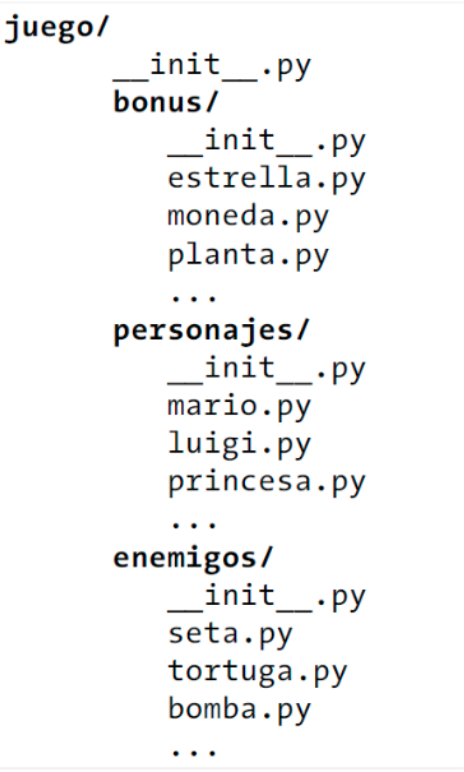

Un módulo es un fichero .py

Los módulos pueden organizarse en paquetes​

Un paquete es una carpeta que contiene un fichero​ `__init__.py​`

Por ejemplo, vamos a crear un módulo para guardar la función que encuentra raíces de segundo grado.

Podemos abrir cualquier editor (incluído el que trae el propio colab), o alternativamente podemos preceder la celda con la "función magic" (que aporta Colab y se denotan por empezar con `%` o `%%`), en este caso `%%writefile`

El resultado es dejar la definición de la función en un archivo llamado `cuadratica.py` con el código de nuestra función en el mismo directorio donde tenemos el notebook (el archivo .ipynb)

In [ ]:
%%writefile cuadratica.py

def raices(a, b=0, c=0):
    """ dados los coeficientes,
        encuentra los valores de x tal que
        así: ax^2 + bx + c = 0
    """
    discriminante = (b**2 - 4*a*c)**0.5
    x1 = (-b + discriminante)/(2*a)
    x2 = (-b - discriminante)/(2*a)
    return (x1, x2)



Writing cuadratica.py


Lo hemos guardado en un archivo `cuadratica.py` en el directorio donde estamos corriendo esta consola (notebook), entonces directamente podemos **importar** ese módulo.

In [ ]:
import cuadratica

El módulo `cuadratica` importado funciona como *"espacio de nombres"*, donde todos los objetos definidos dentro son atributos

In [ ]:
cuadratica.raices??

In [ ]:
cuadratica.raices(3, 2, -1)

(0.3333333333333333, -1.0)

In [ ]:
cuadratica.raices(3, 2, 1)

((-0.3333333333333333+0.47140452079103173j),
 (-0.3333333333333333-0.47140452079103173j))

Importar un modulo es importar un "espacio de nombres", donde todo lo que el modulo contenga (funciones, clases, constantes, etc.) se accederá como un atributo del modulo de la forma  `modulo.<objeto>`

Cuando el nombre del espacio de nombres es muy largo, podemos ponerle un alias


In [ ]:
# igual que la primera forma pero poniendole un alias (más breve).
import cuadratica as cuad

cuad.raices(24,6,-5)

(0.3482423621500228, -0.5982423621500228)

Si **solo queremos alguna unidad de código y no todo el módulo**, entonces podemos hacer una importación selectiva

In [ ]:
# solo importa el "objeto" que indiquemos y lo deja
# en el espacio de nombres desde el que estamos importando
from cuadratica import raices

In [ ]:
raices?

Si, como sucede en general, el módulo definiera más de una unidad de código (una función, clase, constantes, etc.) podemos usar una tupla para importar varias cosas cosas al espacio de nombres actual. Por ejemplo:

```python
from cuadratica import raices, integral, diferencial
```

Por último, si queremos importar todo pero no usar el prefijo, podemos usar el `*`. **Esto no es recomendado**
    
```python
from cuadratica import *
```

### Paquetes: módulos de módulos

Cuando tenemos muchos módulos que están relacionados es bueno crear un **paquete**. Un paquete de modulos es un simple directorio con un módulo especial llamado `__init__.py` (que puede estar vacio) y tantos modulos y subpaquetes como queramos.


Los paquetes se usan igual que un módulo. Por ejemplo, supongamos que tenemos una estructura

```python
    paquete/
       __init__.py
       modulo.py
```
Puedo importar la `funcion_loca` definida en `modulo.py` así
```python
    from paquete.modulo import funcion_loca
```







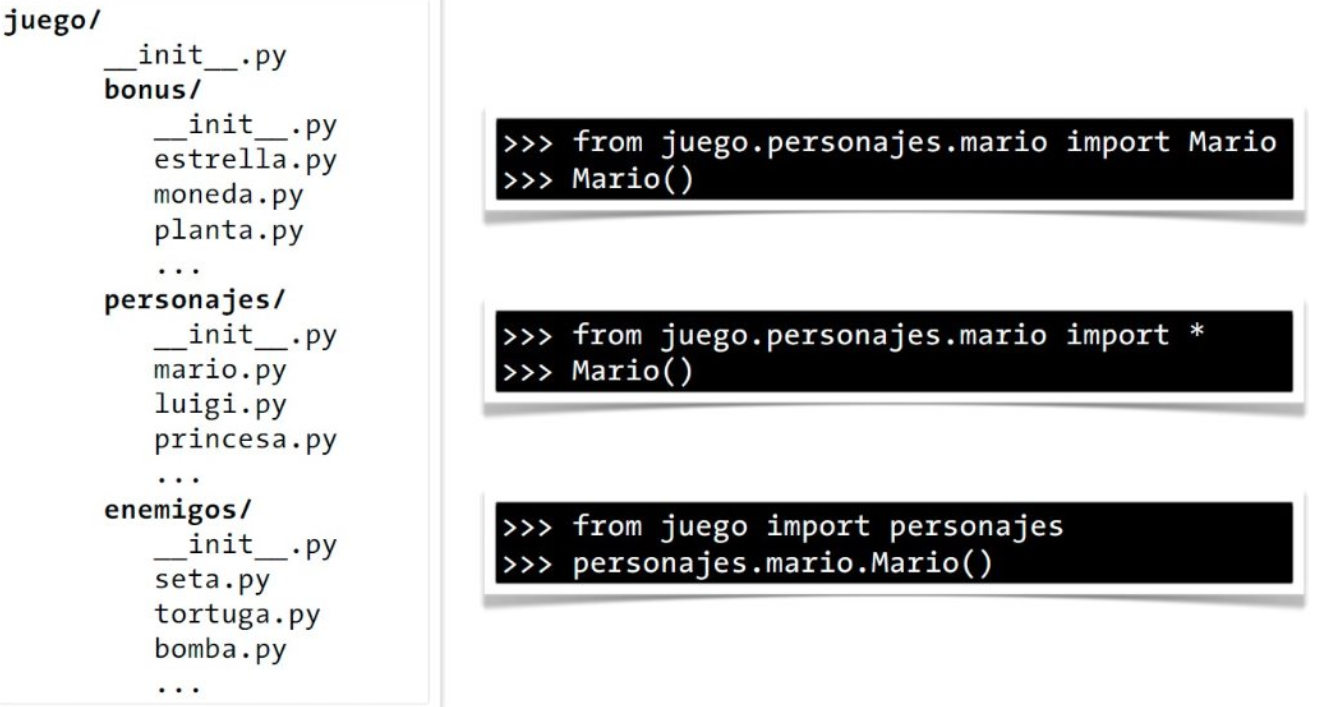

In [ ]:
%mkdir paquete             # creamos un directorio  "paquete"

In [ ]:
%%writefile paquete/__init__.py



Writing paquete/__init__.py


In [ ]:
%%writefile paquete/modulo.py

def funcion_loca(w=300,h=200):
    _                                      =   (
                                        255,
                                      lambda
                               V       ,B,c
                             :c   and Y(V*V+B,B,  c
                               -1)if(abs(V)<6)else
               (              2+c-4*abs(V)**-.4)/i
                 )  ;v,      x=w,h; C = range(-1,v*x
                  +1);import  struct; P = struct.pack;M, \
            j  =b'<QIIHHHH',open('M.bmp','wb').write; k= v,x,1,24
    for X in C or 'Mandelbrot. Adapted to Python3 by @tin_nqn_':
        j(b'BM' + P(M, v*x*3+26, 26, 12,*k)) if X==-1 else 0; i,\
            Y=_;j(P(b'BBB',*(lambda T: map(int, (T*80+T**9
                  *i-950*T  **99,T*70-880*T**18 + 701*
                 T  **9     ,T*i**(1-T**45*2))))(sum(
               [              Y(0,(A%3/3.+X%v+(X/v+
                               A/3/3.-x/2)/1j)*2.5
                             /x   -2.7,i)**2 for  \
                               A       in C
                                      [:9]])
                                        /9)
                                       )   )

Writing paquete/modulo.py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#import paquete
#paquete.modulo.funcion_loca()
from paquete import modulo as m
m.funcion_loca()

# puedes ver el resultado creando una celda tipo Markdown
# con el contenido o si abres el fichero que se ha generado en la carpeta files:
#
#![](M.bmp)

<img src='https://drive.google.com/uc?id=1nwlQ3ntm8o1n51vAgxZAIV-yzowp9TK_'>


##  Ejercicios S6.9. Módulos y paquetes

In [ ]:
import circunferencia as circle


#### S6.9.2. Desde una celda de la sesión intereactiva, importe todo el módulo como un alias `circle` y verifique `circle.PI` y `circle.area()`. Luego importe utilizando la forma `from circunferencia import ...` que importe también la función y la constante

In [ ]:
import circunferencia as circle

print(circle.PI)
print(circle.area(5))

from circunferencia import PI, area

print(PI)
print(area(5))

3.14159
78.53975
3.14159
78.53975


#### S6.9.3. Verifica que circle.area y área son el mismo objeto

In [ ]:
from circunferencia import PI, area

print(circle.area is area)

True


#### S6.9.4. Crea un paquete `geometria` que contenga el modulo `circunferencia` creado anterioriomente y otro análogo que se llame `rectangulo` que contenga tambien una función `area`, con el cálculo correspondiente.

In [1]:
#Crear un directorio geometria con los modulos circunferencia.py y rectangulo.py
%mkdir -p geometria



In [2]:
%%writefile geometria/__init__.py

Writing geometria/__init__.py


In [3]:
%%writefile geometria/circunferencia.py

PI = 3.14159
pi = PI

def area(r):
    return PI * r ** 2

Writing geometria/circunferencia.py


#### S6.9.4. Verifica

    * `import geometria`,
    * `from geometria import rectangulo`,
    * `from geometria.circunferencia import pi, area`
    * `from geometria.rectangulo import area as area_rect`
    

In [4]:
!ls -l geometria

total 8
-rw-r--r-- 1 root root 59 Oct 30 12:47 circunferencia.py
-rw-r--r-- 1 root root  1 Oct 30 12:47 __init__.py


In [5]:
%%writefile geometria/rectangulo.py
def area(base, altura):
    return base * altura

Writing geometria/rectangulo.py


In [6]:
import geometria

from geometria import rectangulo
from geometria.circunferencia import pi, area

from geometria.rectangulo import area as area_rect

print(pi)
print(area(5))
print(area_rect(4, 5))

3.14159
78.53975
20


# S6.10. Biblioteca estándar: las baterías puestas de Python

Sin entrar en detalles, ya utilizamos algunos módulos que trae python, por ejemplo cuando importamos el módulo `math` para usar las funciones matemáticas y constantes que define
    
    import math


Hay muchísimas más funcionalidades que vienen incorporadas al lenguaje y están estandarizadas para que funcionen (salvo casos específicos) de la misma manera en cualquier implementación de Python y sistema operativo. Es lo que se conoce como la [biblioteca estándar de python](http://docs.python.org/3/library/) y es muy amplia y potente.

Además de funciones matemáticas, manejo de algunos formatos de archivos más específicos que el "texto plano", protocolos de internet, otras *clases* de números y estructuras de datos,  etc.


## CSV y JSON

### CSV

[CSV](https://es.wikipedia.org/wiki/CSV) (Comma Separated Values) es un formato de archivo abierto (un archivo de texto) para datos compartir datos estructurados tipo tabla.

Es muy simple y básica pero muy usado para intercambiar información estructurada entre distintos programas. Por ejemplo, desde Excel o Libreoffice Calc se pueden guardar (y abrir) archivos CSV y python nos proporciona librerías integradas para gestionar dichos archivos.

<img src='https://drive.google.com/uc?id=1_CE1jQVJ5fJoYEYArd5WxJ2yzLnGV2vs' width='200'>

Ver [documentación](https://docs.python.org/3/library/csv.html)


In [ ]:
!cat data/near_critical_oil.csv

Component,Mol fraction
n2,0.46
co2,3.36
c1,62.36
c2,8.9
c3,5.31
c4,3.01
c5,1.5
c6,1.05
c7,2.0
c7+,12.049


In [ ]:
import csv

with open('data/near_critical_oil.csv') as csv_file:
    reader = csv.reader(csv_file)
    critical_oil = [line for line in reader]   #o list(reader)
critical_oil

FileNotFoundError: [Errno 2] No such file or directory: 'data/near_critical_oil.csv'

Para escribir creamos un objeto writer y usa

In [ ]:
datos = [('Nombre', 'Peso'), ('Juan', 92), ('La "Mole" Moli', 121), ('Martín', '5 kilos de más')]

with open('pesos.csv', 'w') as pesos_csv:
    writer = csv.writer(pesos_csv)
    writer.writerows(datos)

In [ ]:
%cat pesos.csv

## Ejercicios  S6.10.  Biblioteca estándar

In [7]:
%%writefile circuitos.csv
long;lat;CODIGO DE ESTABLECIMIENTO;NOMBRE ESTABLECIMIENTO;DOMICILIO;CIRCUITO;DESDE MESA;HASTA MESA;TOTAL MESAS;Dirección Normalizada
-58.372807778869245;-34.622409314430783;4369;ESC N°3 BERNARDINO RIVADAVIA;BOLIVAR 1235;1;19;28;10;BOLIVAR 1235
-58.384400577996836;-34.593569986274616;4593;COL. NAC.Nº2 D F SARMIENTO;LIBERTAD 1257;6;115;136;22;LIBERTAD 1257
-58.373914555842283;-34.602665313935738;4409;ESC N°13 GRAL SAN MARTIN;SAN MARTIN 458;9;192;206;15;SAN MARTIN 458
-58.383791453750931;-34.601733848426591;5330;ESC N°7 PTE ROCA;LIBERTAD 581;10;225;234;10;LIBERTAD 581
-58.388829352224974;-34.605387432219594;9026;UMSA UNIV DE MUSEO SOCIAL ARG;SARMIENTO 1565;10;252;259;8;SARMIENTO 1565
-58.373317952774258;-34.611859568515861;5118;ESC POLITECNICA Nº5 M BELGRANO;BOLIVAR 346;14;367;371;5;BOLIVAR 346
-58.373438804697628;-34.610990941996334;8716;COLEGIO NACIONAL BUENOS AIRES;BOLIVAR 263;14;372;381;10;BOLIVAR 263

Writing circuitos.csv


#### S6.10.1. Dado un archivo CSV `circuitos.csv` (en la siguiente celda), leerlo utilizando `csv.DictReader` en vez de `csv.reader` y devolver todas las filas en una lista. Notar que el delimitador es `;` en vez de coma.  (Puedes basarte en  el código anterior)

In [8]:
import csv
with open('circuitos.csv' , "r" , encoding="utf-8") as archivo:
    lector = csv.DictReader(archivo, delimiter=';')
    filas = list(lector)
print(filas)

[{'long': '-58.372807778869245', 'lat': '-34.622409314430783', 'CODIGO DE ESTABLECIMIENTO': '4369', 'NOMBRE ESTABLECIMIENTO': 'ESC N°3 BERNARDINO RIVADAVIA', 'DOMICILIO': 'BOLIVAR 1235', 'CIRCUITO': '1', 'DESDE MESA': '19', 'HASTA MESA': '28', 'TOTAL MESAS': '10', 'Dirección Normalizada': 'BOLIVAR 1235'}, {'long': '-58.384400577996836', 'lat': '-34.593569986274616', 'CODIGO DE ESTABLECIMIENTO': '4593', 'NOMBRE ESTABLECIMIENTO': 'COL. NAC.Nº2 D F SARMIENTO', 'DOMICILIO': 'LIBERTAD 1257', 'CIRCUITO': '6', 'DESDE MESA': '115', 'HASTA MESA': '136', 'TOTAL MESAS': '22', 'Dirección Normalizada': 'LIBERTAD 1257'}, {'long': '-58.373914555842283', 'lat': '-34.602665313935738', 'CODIGO DE ESTABLECIMIENTO': '4409', 'NOMBRE ESTABLECIMIENTO': 'ESC N°13 GRAL SAN MARTIN', 'DOMICILIO': 'SAN MARTIN 458', 'CIRCUITO': '9', 'DESDE MESA': '192', 'HASTA MESA': '206', 'TOTAL MESAS': '15', 'Dirección Normalizada': 'SAN MARTIN 458'}, {'long': '-58.383791453750931', 'lat': '-34.601733848426591', 'CODIGO DE ESTA

#### S6.10.2. Genera un archivo csv donde la primera columna es la serie de enteros 1 a 10 inclusive, la segunda columna el logaritmo natural para el numero correspondiente de la primera columna, y una tercera que el logaritmo en base 10, separados por tabuladores.

In [9]:
import csv
import math

with open("logaritmos.csv", "w", newline="", encoding="utf-8") as archivo:
    escritor = csv.writer(archivo, delimiter="\t")

    escritor.writerow(["Numero", "Logaritmo natural", "Logaritmo base 10"])

    for numero in range(1, 11):
        escritor.writerow([numero, math.log(numero), math.log10(numero)])

In [10]:
with open("logaritmos.csv", "r") as archivo:
    print(archivo.read())

Numero	Logaritmo natural	Logaritmo base 10
1	0.0	0.0
2	0.6931471805599453	0.3010299956639812
3	1.0986122886681098	0.47712125471966244
4	1.3862943611198906	0.6020599913279624
5	1.6094379124341003	0.6989700043360189
6	1.791759469228055	0.7781512503836436
7	1.9459101490553132	0.8450980400142568
8	2.0794415416798357	0.9030899869919435
9	2.1972245773362196	0.9542425094393249
10	2.302585092994046	1.0



## Ejercicios ficheros CSV

#### Leyendo un Archivo CSV

Veamos cómo leer un archivo CSV usando los módulos de ayuda que hemos discutido arriba.

Crea tu archivo CSV y guárdalo como ejemplo.csv. Asegura que tiene la extensión .csv y llena algunos datos. Aquí tenemos nuestro archivo CSV el cual contiene los nombres de los estudiantes y el grado en al que pertenecen.
<img src='https://drive.google.com/uc?id=1USI0ckSejw_M_OW0WcWJe3E1GvYnA40d' width= '500'>

In [11]:
%%writefile ejemplo.csv
Nombre,Apellido,Grado
Alejandro,Ramírez,A
Tomás,López,B
María,García,A

Writing ejemplo.csv


In [13]:
import csv

with open('ejemplo.csv') as csvArchivo:
    lectura = csv.reader(csvArchivo,
                         dialect='excel')
    for fila in lectura:
        print(fila)

['Nombre', 'Apellido', 'Grado']
['Alejandro', 'Ramírez', 'A']
['Tomás', 'López', 'B']
['María', 'García', 'A']


**NOTA**: comprobamos que el delimitador que encuentra es ;

In [14]:
import csv

with open('ejemplo.csv') as csvArchivo:
    lectura = csv.reader(csvArchivo,
                         delimiter=',',
                         quotechar='"',
                        quoting=csv.QUOTE_MINIMAL)
    for fila in lectura:
        a,b,c = fila
        print(f"{a:<10} {b:<10} {c:>5}")

Nombre     Apellido   Grado
Alejandro  Ramírez        A
Tomás      López          B
María      García         A


En el código de arriba, importamos el módulo CSV y después abrimos nuestro archivo CSV como File. Entonces definimos el objeto lector y usamos el método csv.reader para extraer los datos al objeto. Entonces iteramos sobre el objeto reader y recuperamos cada fila de nuestros datos.

Primero importamos el módulo csv e inicializamos una lista vacía resultado la cuál usaremos para almacenar los datos recuperados. Después definimos el objeto entrada y usamos el método csv.DictReader para extraer los datos en el objeto. Entonces iteramos el objeto entrada y recuperamos cada fila de nuestros datos.

Finalmente, adjuntamos cada fila a la lista de resultados e imprimimos los contenidos a la consola.

In [15]:
import csv

datos = [["Nombre", "Apellido", "Grado"],
          ['Alejandro', 'Ramírez', 'A'],
          ['Tomás', 'López', 'B']]

miArchivo = open('ejemplo2.csv', 'w')
with miArchivo:
    salida = csv.writer(miArchivo)
    salida.writerows(datos)

print("Fin grabación")

Fin grabación


<img src='https://drive.google.com/uc?id=1bSSALbPTRBv0-E_vrgzETM9P8NJW0hHl' width= '500'>

In [17]:
%%writefile libro2.csv
Nombre;Apellido;Edad;Ciudad;Curso
Juan;Garcia;20;Murcia;DAM
Ana;Lopez;22;Elche;DAW
Pedro;Martinez;21;Alicante;DAM

Writing libro2.csv


In [19]:
import csv

with open('libro2.csv') as csvArchivo:
    lectura = csv.reader(csvArchivo,
                         delimiter=';',
                         quotechar=',',
                         quoting=csv.QUOTE_MINIMAL)
    for fila in lectura:
        a,b,c,d,e = fila
        print(f"{a:<10} {b:>10} {c:>8} {d:>8}")

Nombre       Apellido     Edad   Ciudad
Juan           Garcia       20   Murcia
Ana             Lopez       22    Elche
Pedro        Martinez       21 Alicante


Tabla hombres según el número de hijos, grado de urbanización del municipio en el que residen y edad. National. Encuesta de Fecundidad obtenidos de :
https://datos.gob.es/es/catalogo/ea0010587-hombres-segun-el-numero-de-hijos-grado-de-urbanizacion-del-municipio-en-el-que-residen-y-edad-identificador-api-30316

1. Opción csv separado por coma

In [20]:
import csv

with open('encuesta_fecundidad.csv', newline='', encoding='utf-8') as csvArchivo:
    lectura = csv.reader(csvArchivo, dialect='excel', delimiter=';')
    for a,b,c,d in lectura:
        print(f"{a:24} {b:<20} {c:<16} {d:>6}")

FileNotFoundError: [Errno 2] No such file or directory: 'encuesta_fecundidad.csv'

2. Opción Tab separated:

In [ ]:
import csv

with open('encuesta_fecundidad2.csv',
          newline='',
          encoding='utf-8') as csvArchivo:
    lectura = csv.reader(csvArchivo, dialect='excel-tab')
    for a,b,c,d in lectura:
        print(f"{a:24} {b:<20} {c:<15} {d:>6}")

#### Realizar los mismos ejercicios para la siguiente tabla:

Table of INEBase Hombres parados según el número de hijos, número de años que llevan desempleados y edad. National. Encuesta de Fecundidad

https://datos.gob.es/es/catalogo/ea0010587-hombres-parados-segun-el-numero-de-hijos-numero-de-anos-que-llevan-desempleados-y-edad-identificador-api-30331


In [21]:
import csv

with open("/content/30331.csv", "r", encoding="utf-8-sig", newline="") as archivo:
    lector = csv.reader(archivo, delimiter=";")

    for fila in lector:
        print(fila)

['Tiempo parado', 'Edad', 'Número de hijos', 'Total']
['Total', 'Total', 'Total', '1.412.285']
['Total', 'Total', 'Sin hijos', '803.087']
['Total', 'Total', 'Con hijos', '609.198']
['Total', 'Total', '1 hijo', '215.191']
['Total', 'Total', '2 y más hijos', '394.007']
['Total', 'Total', 'Número medio de hijos', '0,87']
['Total', 'Menos de 30 años', 'Total', '386.552']
['Total', 'Menos de 30 años', 'Sin hijos', '357.017']
['Total', 'Menos de 30 años', 'Con hijos', '29.536']
['Total', 'Menos de 30 años', '1 hijo', '14.065']
['Total', 'Menos de 30 años', '2 y más hijos', '15.471']
['Total', 'Menos de 30 años', 'Número medio de hijos', '0,15']
['Total', 'De 30 a 34 años', 'Total', '141.143']
['Total', 'De 30 a 34 años', 'Sin hijos', '109.354']
['Total', 'De 30 a 34 años', 'Con hijos', '31.789']
['Total', 'De 30 a 34 años', '1 hijo', '14.771']
['Total', 'De 30 a 34 años', '2 y más hijos', '17.018']
['Total', 'De 30 a 34 años', 'Número medio de hijos', '0,42']
['Total', 'De 35 a 39 años', 'To

Nota: Si tenemos que manejar muchos ficheros csv, existe una mejora utilizando los módulos numpy o panda que veremos más adelante.


## JSON
### Introducción
El formato de archivo JSON es uno de los más populares en los últimos años para la serialización de datos. Los archivos de este formato se pueden obtener como resultados de la mayoría de las aplicaciones API REST y otras aplicaciones web. Debido a su gran popularidad es cada vez más probable que se necesite leer o escribir archivos JSON con Python.

En Python el formato JSON se puede procesar gracias al paquete **json**. Este paquete contiene el código que permite transformar los archivos JSON en diccionarios o viceversa.

JSON es en la actualidad utilizado por casi todos los servicios web para el envío y recepción de datos.

A partir de la versión 2.6 Python incorpora en su librería estándar el módulo **json**, con una API similar a la de **pickle**, para codificar y decodificar información en el formato JSON. «Codificar» y «decodificar» deben ser entendidos como convertir de un objeto Python a JSON y viceversa.

### El formato JSON
JSON es un formato para el intercambio de datos basado en texto. Por lo que es fácil de leer tanto para una persona como para una maquina. El nombre es un acrónimo de las siglas en inglés de JavaScript Object Notation. Lo que indica que su origen se encuentra vinculado al lenguaje JavaScript. Aunque hoy en día puede ser utilizado desde casi todos los lenguajes de programación, JSON se ha hecho fuerte como alternativa a XML, otro formato de intercambio de datos que requiere más metainformación y, por lo tanto, consume más ancho de banda y recursos.

Los datos en los archivos JSON son pares de "**propiedad:valor**" separados por dos puntos. Estos pares se separan mediante comas y se encierran entre llaves. El valor de una propiedad puede ser otro objeto JSON, lo que ofrece una gran flexibilidad a la hora de estructurar información. Esta estructura de datos recuerda mucho a los diccionarios de Python.

### Escribir archivos JSON con Python

La forma más sencilla de generar un archivo JSON desde Python es exportar los datos contenidos en un objeto diccionario. Al igual que los objetos JSON, los objeto diccionarios pueden contener cualquier tipo de datos: valores numéricos, cadena de textos, vectores o cualquier otro tipo de objeto. El código necesario para traducir el diccionario a formato JSON se encuentra disponible en el paquete json.

A continuación, se muestra un ejemplo. Inicialmente se importa el paquete json, posteriormente se crea un objeto diccionario al que se agregan los datos de tres clientes entre los que se encuentra el nombre los apellidos, la edad y la cantidad gastada por cada uno. En el ejemplo se pude apreciar la utilización de diferentes tipos de datos como cadena de texto, valores reales y vectores. Otra cosa que se puede apreciar es que una misma propiedad puede tener diferentes datos en cada registro. Lo que no se puede conseguir en otros formatos como CSV. Finalmente se abre un archivo y se vuelca en el mismo los datos del diccionario utilizando **json.dump** (grabamos el diccionario como un único objeto serializable).

Nota: el resultado es siempre una cadena (str en Python 3 y unicode en Python 2).

Nota: el parámetro **ident** indica la sangría.

In [23]:
import json

lista = {}# diccionario vacío
# añadimos un valor al diccionario con clave "clientes" y valor una lista vacía []
# como único valor
# lista{'clientes':[]}
lista['clientes'] = []
#cada objeto de la lista es un diccionario
#{'nombre': valor1,'apellidos':valor2,'edad:valor3,'importe':valor4}
lista['clientes'].append({
    'nombre': 'Maribel',
    'apellidos': 'Paredes Ruiz',
    'edad': 27,
    'importe': 7.17})
lista['clientes'].append({
    'nombre': 'José',
    'apellidos': 'Hernández Jarabo',
    'edad': 31,
    'importe': [1.90, 5.50]})
lista['clientes'].append({
    'nombre': 'Teodoro',
    'apellidos': 'Rivera Pardo',
    'edad': 36,
    'importe': 1.11})

with open('datos.json', 'w') as jsonArchivo:
    json.dump(lista, jsonArchivo,
              indent=4,
              ensure_ascii=False)

Al ejecutar este código se genera un archivo datos.json en el que se pueden observar los datos. En este archivo todos los datos se encuentran en una única línea, ocupando el mínimo espacio posible. Una vez formateado para facilitar la lectura a las personas se puede observar en la siguiente captura de pantalla.

<img src='https://drive.google.com/uc?id=1c7WHXlAKBUnYIGQ7EKpClJZFUVuCPO7C' width= '400'>

Se ha creado un diccionario con un único objeto clave:valor: **{"clientes":[lista de objetos de tipo diccionario]}**.

Cada objeto de la lista es de tipo diccionario con la estructura:

Este comportamiento por defecto es el más adecuado ya que reduce el tamaño de los archivos generados y por lo tanto reduce el ancho de banda necesario. En caso de que sea necesario obtener archivos JSON formateados para que puedan ser fácilmente leídos por personas se puede utilizar la opción **indent** para la indentación de los valores.

Si en vez de grabar una lista de clientes queremos grabar un solo registro:

In [24]:
import json

cliente = {'nombre': 'Maribel','apellidos': 'Paredes Ruiz','edad': 27,'importe': 7.17}

with open('cliente.json', 'w') as jsonArchivo:
    json.dump(cliente, jsonArchivo,
              indent=4,
              ensure_ascii=False)

### Leer archivos JSON con Python
Para decodificar una cadena en el formato JSON (es decir, convertirla a un objeto de Python), utilizamos load.

La lectura de archivos JSON es similar al proceso de escritura. Se ha de abrir un archivo y procesar este utilizando el método **json.load**. El cual **devolverá un objeto de tipo diccionario sobre el que se puede iterar**. A modo de ejemplo se puede importar el archivo generado anteriormente y sacar los resultados por pantalla utilizando el siguiente código.

In [25]:
import json

with open('datos.json') as jsonArchivo:
    lista = json.load(jsonArchivo) #leemos un registro con una lista asociada a la clave

#el valor que devuelve lista['clientes'] es una lista (iterable) en la que cada objeto es un diccionario
for cliente in lista['clientes']:#cliente es un diccionario
    print('Nombre:', cliente['nombre'])
    print('Apellidos:', cliente['apellidos'])
    print('Edad:', cliente['edad'])
    print('Importe:', cliente['importe'])
    print('')

Nombre: Maribel
Apellidos: Paredes Ruiz
Edad: 27
Importe: 7.17

Nombre: José
Apellidos: Hernández Jarabo
Edad: 31
Importe: [1.9, 5.5]

Nombre: Teodoro
Apellidos: Rivera Pardo
Edad: 36
Importe: 1.11



Si queremos leer el archivo cliente.json que solo tenía un registro:

In [26]:
import json

with open('cliente.json') as jsonArchivo:
    registro = json.load(jsonArchivo) #leemos el único registro que contiene el diccionario
#print(registro)
print()
print('Nombre:', registro['nombre'])
print('Apellidos:', registro['apellidos'])
print('Edad:', registro['edad'])
print('Importe:', registro['importe'])
print()

#otra forma es leer el diccionario
for key, valor in registro.items():
    print (f"{key:<15}: {valor:<30}")


Nombre: Maribel
Apellidos: Paredes Ruiz
Edad: 27
Importe: 7.17

nombre         : Maribel                       
apellidos      : Paredes Ruiz                  
edad           : 27                            
importe        : 7.17                          


Este ejercicio es el que hemos resuelto en csv y, aunque no sea directo, lo resolveremos transformando los campos necesarios:

In [27]:
with open('encuesta_fecundidad.json',
          encoding = 'utf-8') as jsonArchivo:
    lista = json.load(jsonArchivo)
#print(lista)
#print()
print(lista[0])
print()
print("Grado de urbanización     Edad                 Número de hijos  Total")
for fila in lista:
    #print(fila)
    #print(fila['Nombre'])
    #print(fila['Data'])
    lista1 = fila['Nombre'].split(',')#tres primeras columnas
    dic = fila['Data'][0]#cuarta columna
    valor = dic['Valor']
    if valor == None:#corrige un error en el que el valor es
        valor = 0
    print(f"{lista1[0]:<24} {lista1[1]:<20} {lista1[2]:<16} {valor:>6.2f}")


FileNotFoundError: [Errno 2] No such file or directory: 'encuesta_fecundidad.json'

Resolvemos el ejercicio anterior descargando directamente la url:

In [28]:
import json
import requests
url = 'https://servicios.ine.es/wstempus/js/es/DATOS_TABLA/t20/p317/a2018/def/p02/e02/01005.px?tip=AM'
resp = requests.get(url)
lista = json.loads(resp.content)

print("Grado de urbanización     Edad                 Número de hijos  Total")
for fila in lista:
    lista1 = fila['Nombre'].split(',')
    dic = fila['Data'][0]
    valor = dic['Valor']
    if valor == None:#corrige un error en el que el valor es null
        valor = 0
    print(f"{lista1[0]:<24} {lista1[1]:<20} {lista1[2]:<16} {valor:>6.2f}")


Grado de urbanización     Edad                 Número de hijos  Total
Total                     Total                Total           100.00
Total                     Total                Sin hijos        49.04
Total                     Total                Con hijos        50.96
Total                     Total                1 hijo           17.93
Total                     Total                2 y más hijos    33.03
Total                     Menos de 30 años     Total           100.00
Total                     Menos de 30 años     Sin hijos        95.12
Total                     Menos de 30 años     Con hijos         4.88
Total                     Menos de 30 años     1 hijo            4.26
Total                     Menos de 30 años     2 y más hijos     0.62
Total                     De 30 a 34 años      Total           100.00
Total                     De 30 a 34 años      Sin hijos        62.85
Total                     De 30 a 34 años      Con hijos        37.15
Total               

### Convertir una cadena de texto con JSON en un diccionario

Al igual que anteriormente también se puede convertir una cadena de texto que contiene un objeto JSON en un diccionario de Python. Para esto se ha de utilizar el método **json.loads**. Este método es de gran utilidad cuando como resultado de un servicio web se obtiene una cadena de texto con un objeto JSON, el cual se puede transforma fácilmente en un diccionario.

En el siguiente ejemplo se muestra como se procesan los resultados de consultar un API donde existe un único registro json:

In [29]:
import requests
resp = requests.get('http://ip-api.com/json/208.80.152.201')
dic = json.loads(resp.content)
print(dic)#el registro tiene un único objeto que es un diccionario
print()

print(f"{'clave':<15} {'valor':^30}")
for key, valor in dic.items():
    print (f"{key:<15}  {valor:<30}")

{'status': 'success', 'country': 'United States', 'countryCode': 'US', 'region': 'CA', 'regionName': 'California', 'city': 'San Francisco', 'zip': '94104', 'lat': 37.7892, 'lon': -122.402, 'timezone': 'America/Los_Angeles', 'isp': 'Wikimedia Foundation Inc.', 'org': 'Wikimedia Foundation Inc', 'as': 'AS14907 Wikimedia Foundation Inc.', 'query': '208.80.152.201'}

clave                       valor             
status           success                       
country          United States                 
countryCode      US                            
region           CA                            
regionName       California                    
city             San Francisco                 
zip              94104                         
lat              37.7892                       
lon              -122.402                      
timezone         America/Los_Angeles           
isp              Wikimedia Foundation Inc.     
org              Wikimedia Foundation Inc      
as         

### Opciones

El comportamiento de la librería json se puede personalizar utilizando diferentes opciones. Entre algunas de las opciones que se pueden configurar se encuentra la codificación y la ordenación.

#### Codificación Unicode

Una de las opciones más importantes puede ser la codificación de texto empleada en el archivo.Por defecto el paquete json genera los archivos en código ASCII. Cuando existen caracteres no ASCII estos serán escapados, aunque puede ser más interesante utilizar en estos casos codificación Unicode. Para conseguir este cambio solamente se ha de configurar la opción **ensure_ascii = False**. La diferencia se puede apreciar en el siguiente ejemplo.

In [30]:
dic = {'nombre': 'Daniel', 'apellidos': 'Rodríguez Pardo'}
json.dumps(dic)

'{"nombre": "Daniel", "apellidos": "Rodr\\u00edguez Pardo"}'

In [31]:
json.dumps(dic, ensure_ascii=False)

'{"nombre": "Daniel", "apellidos": "Rodríguez Pardo"}'

### Ordenación

Los objetos JSON son una colección desordenada de conjuntos de para clave valor. El orden de los datos se encuentra definido por la posición en la que estos aparecen en el archivo.

En el caos de que sea necesario ordenarlos por la calve se puede configurar la opción **sort_keys = True**. El resultado de utilizar esta opción se pude ver en el siguiente ejemplo.

In [32]:
json.dumps(data, sort_keys=True, ensure_ascii=False)

NameError: name 'data' is not defined

### Ejercicios

Convertir de Python a JSON:

In [ ]:
import json

dic = {
"País":"España",
"Comunidad":"Madrid",
"Ciudad":"Alcobendas"
}

# convertir a JSON:

res = json.dumps(dic,ensure_ascii=False)

#El resultado es un string de JSON:

print(res)
print()

# lo guardamos en un fichero
with open('ejercicio1.json', 'w') as jsonArchivo:
    json.dump(dic, jsonArchivo,
              indent=4,
              ensure_ascii=False)

# lo leemos del fichero y lo volvemos a imprimir
with open('ejercicio1.json') as jsonArchivo:
    reg = json.load(jsonArchivo)
    print(f"País......: {reg['País']} \nComunidad.: {reg['Comunidad']} \nCiudad....: {reg['Ciudad']}")


Puede convertir objetos de Python de los siguientes tipos, en cadenas JSON:

    dict
    list
    tuple
    string
    int

In [33]:
import json

print(json.dumps({"País":"España", "Comunidad":"Madrid",}, ensure_ascii=False))
print(json.dumps(["Aranjuez","Las Rozas"]))
print(json.dumps(("Aranjuez","Las Rozas")))
print(json.dumps("Catalina"))
print(json.dumps(32))
print(json.dumps(32.10))
print(json.dumps(True))
print(json.dumps(False))
print(json.dumps(None))

{"País": "España", "Comunidad": "Madrid"}
["Aranjuez", "Las Rozas"]
["Aranjuez", "Las Rozas"]
"Catalina"
32
32.1
true
false
null


Use el parámetro de sangría (**ident**) para definir los números de sangría:

In [34]:
import json

reg = {
"Nombre":"Ricardo",
"Apellido":"Rodriguez",
"teléfono": 600000000,
"email":"ricardo@bodega.com",
"Segmento": ("AA"),
"N Compras":7,
"Productos comprados": [
{"Vino":"Vino tinto","Grados":14},
{"Vino":"Vino Blanco","Grados":11.5}
  ]
}

print(json.dumps(reg,indent=5, ensure_ascii=False))

{
     "Nombre": "Ricardo",
     "Apellido": "Rodriguez",
     "teléfono": 600000000,
     "email": "ricardo@bodega.com",
     "Segmento": "AA",
     "N Compras": 7,
     "Productos comprados": [
          {
               "Vino": "Vino tinto",
               "Grados": 14
          },
          {
               "Vino": "Vino Blanco",
               "Grados": 11.5
          }
     ]
}


In [35]:
import json

cadena="""
  {
      "código":"1",
      "descripción":"patatas",
      "precio":"13.45"
  }
"""
print(cadena) # imprimimos un string
diccionario=json.loads(cadena)
print(diccionario) # imprimimos un diccionario


  {
      "código":"1",
      "descripción":"patatas",
      "precio":"13.45"
  }

{'código': '1', 'descripción': 'patatas', 'precio': '13.45'}


In [36]:
import json

cadena="""
[
  {
      "código":"1",
      "descripción":"patatas",
      "precio":"13.45"
  },
  {
      "código":"2",
      "descripción":"manzanas",
      "precio":"45"
  }
]
"""
print(cadena) # imprimimos un string
lista=json.loads(cadena)
print(lista) # imprimimos una lista


[
  {
      "código":"1",
      "descripción":"patatas",
      "precio":"13.45"
  },
  {
      "código":"2",
      "descripción":"manzanas",
      "precio":"45"
  }
]

[{'código': '1', 'descripción': 'patatas', 'precio': '13.45'}, {'código': '2', 'descripción': 'manzanas', 'precio': '45'}]


In [ ]:
data = json.loads('[null, true, false, "Hola, mundo!"]')
print(data[1])
data[3]

In [ ]:
d = json.loads('{"url": "recursospython.com", "sitio": "Recursos Python"}')
print(d["url"])
d["sitio"]

In [ ]:
import json

users = '''
[
{ "id" : "001",
"edad" : "21",
"nombre" : "Luis"
},
{ "id" : "002",
"edad" : "25",
"nombre" : "Andres"
},
{ "id" : "003",
"edad" : "34",
"nombre" : "Jose"
},
{ "id" : "004",
"edad" : "29",
"nombre" : "Jesus"
}
]'''

info = json.loads(users)
print('Cantidad de usuarios:', len(info))
for elemento in info:
    print('Nombre', elemento['nombre'])
    print('Id', elemento['id'])
    print('Edad', elemento['edad'])
    print("n")

Realizar los mismos ejercicios para la siguiente tabla:

Table of INEBase Hombres parados según el número de hijos, número de años que llevan desempleados y edad. National. Encuesta de Fecundidad

https://datos.gob.es/es/catalogo/ea0010587-hombres-con-pareja-segun-el-numero-de-hijos-empleo-actual-de-la-pareja-y-edad-identificador-api-30424

In [37]:
import requests
import json

# Obtenemos los datos de la tabla del INE
url = "https://servicios.ine.es/wstempus/js/ES/DATOS_TABLA/30244"

respuesta = requests.get(url)
respuesta.raise_for_status()

# Convertimos la respuesta JSON en datos de Python
datos = respuesta.json()

# Mostramos los primeros registros
print(json.dumps(datos[:3], indent=4, ensure_ascii=False))

[
    {
        "Nombre": "Total, Total, Total",
        "Data": [
            {
                "Valor": 100.0,
                "Secreto": false
            }
        ]
    },
    {
        "Nombre": "Total, Total, Sin hijos",
        "Data": [
            {
                "Valor": 40.38,
                "Secreto": false
            }
        ]
    },
    {
        "Nombre": "Total, Total, Con hijos",
        "Data": [
            {
                "Valor": 59.62,
                "Secreto": false
            }
        ]
    }
]


# S6.11. Números aleatorios

Todas las funciones relacionadas a la aleatoriedad están en el módulo `random`.

Ver [documentación](https://docs.python.org/3/library/random.html)

In [ ]:
import random

# la función más básica
random.random()                      # float aleatorio, 0.0 <= x < 1.0

0.7255447343078398

In [ ]:
random.randrange(-10, 11, 2)           # análogo a range() devuelve un numero aleatorio de la serie

-10

In [ ]:
random.choice([0.3, 10, 'A'])     # elige un elemento al azar de una secuencia no vacía

0.3

In [ ]:
l = list(range(10))
l

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [ ]:
random.sample(l, k=5)      # elige k elementos de la poblacion dada

[3, 7, 4, 9, 5]

In [ ]:
random.shuffle(l)       # "desordena" una lista (inline)
l

[6, 2, 0, 4, 1, 9, 7, 3, 5, 8]

También tiene muchas funciones de probabilidad

In [ ]:
[method for method in dir(random) if method.endswith('variate')]

['betavariate',
 'expovariate',
 'gammavariate',
 'lognormvariate',
 'normalvariate',
 'paretovariate',
 'vonmisesvariate',
 'weibullvariate']

In [ ]:
random.normalvariate??

##  Ejercicios S6.11. Números aleatorios

#### S6.11.1. Crear un generador de 1000 números aleatorios pertecientes a una curva de probabilidad normal con media 1 y variancia 0.25.

In [38]:
import random
import math

def generar_numeros():
    for i in range(1000):
        yield random.gauss(1, math.sqrt(0.25))

numeros = generar_numeros()

for numero in numeros:
    print(numero)

0.3328215995279036
1.6655991135159613
0.9900816616625918
1.0455633205653188
1.4021038228167533
1.7094051725970267
0.5905763942445197
1.4508737179550724
0.0874184373774376
0.8471553039117542
2.2065089678475243
0.9228913813813047
1.2090093094041747
1.3555087251658904
1.2040230530085831
0.402370614989527
0.8349562669609683
1.481774322128437
0.8589588536023431
1.5728871468984535
0.5889360712255922
1.3989926833664794
0.5816598596181702
0.26868826577704275
1.0162017564731072
1.0220665607577715
1.653340166160403
1.4077638362329863
0.2665420021786261
1.3427663033795536
0.9653891448499987
0.903618227232609
0.6977696805232895
1.069349304644442
0.3456307008471632
0.7695185969080085
0.639507046869735
1.5596420356562954
1.954339371471084
1.7683934341176308
0.8920657661239288
1.4453994126132206
1.4635311909269126
1.124399963040465
1.245323638317357
1.323891234496349
0.8845172824645724
1.0869775084406228
0.8481929505311043
1.3480518668890493
1.003682415494269
0.7585543132500336
1.013138092507805
1.51

In [39]:
%load solutions/S3_4_1.py

ValueError: 'solutions/S3_4_1.py' was not found in history, as a file, url, nor in the user namespace.

# S6.12. Serialización

A veces queremos **serializar un objeto** cualquiera para poder recuperarlo más adelante. Si sólo nos interesa persistir y recuperar información **a nivel Python** podemos usar el módulo [`pickle`](https://docs.python.org/3.4/library/pickle.html).

In [ ]:
información = ['puede', 'ser', {'casi': [], 'cualquier': 100, 'cosa': ('!',)}]

import pickle
info_serial =  pickle.dumps(información)
print(info_serial)

b'\x80\x03]q\x00(X\x05\x00\x00\x00puedeq\x01X\x03\x00\x00\x00serq\x02}q\x03(X\x04\x00\x00\x00casiq\x04]q\x05X\t\x00\x00\x00cualquierq\x06KdX\x04\x00\x00\x00cosaq\x07X\x01\x00\x00\x00!q\x08\x85q\tue.'


In [ ]:
# en sentido contrario
pickle.loads(info_serial)

In [ ]:
# O bien guardar directamente a un archivo
pickle.dump(información, open('datos.pkl', 'wb'))

In [ ]:
!cat datos.pkl

�]q (X   puedeqX   serq}q(X   casiq]qX	   cualquierqKdX   cosaqX   !q�q	ue.

In [ ]:
pickle.load(open('datos.pkl', 'rb'))

['puede', 'ser', {'casi': [], 'cualquier': 100, 'cosa': ('!',)}]

Siempre que la clase **sea serializable** (es decir, que se base en otras clases serializables), pickle permite serializar instancias de clases arbitrarias.

In [ ]:
class A:
    "una clase que no hace absolutamente nada"
    dato = 45

a = A()

a_serializado = pickle.dumps(a)
a_serializado

b'\x80\x03c__main__\nA\nq\x00)\x81q\x01.'

In [ ]:
type(a_serializado)    # la serializados es como datos binarios "crudos"

bytes

In [ ]:
b= pickle.loads(a_serializado)

In [ ]:
b.dato

45

El objeto reconstruído tiene *el mismo estado* (es identico) al original, pero no es en sí el mismo objeto

In [ ]:
b is a

False

Un detalle importante: para poder deseralizar un objeto arbitrario, su clase debe existir en el espacio de nombres

In [ ]:
del A    # borramos la clase A del espacio de nombres global
pickle.loads(a_serializado)

**pickle** es un tipo de serialización específica para Python. Una alternativa más genérica que muchos otros lenguajes soportan (y es muy típica para compartir datos a traves de "APIs" en la web) es el formato [JSON](https://es.wikipedia.org/wiki/JSON), que funciona igual, pero genera una serialización en formato texto y más legible por humanos

In [ ]:
import json

json.dumps(información)

'["puede", "ser", {"casi": [], "cualquier": 100, "cosa": ["!"]}]'

# S6.13. Ejecutando otros "programas" desde colab y python

Colab permite llamar a programas subyacentes preciendo el comando con un signo de exclamación

In [ ]:
#dir   # Listado de ficheros en windows
#!ls    # Listado de ficheros en  linux  y Mac
#!pwd
#!cat pesos.csv

sample_data
/content
cat: pesos.csv: No such file or directory


Incluso podemos capturar la salida del comando y obtener una lista de textos

In [ ]:
mole = !cat pesos.csv | grep "Mole"
mole

['"La ""Mole"" Moli",121']

Si queremos hacer esto en "Python puro", por ejemplo porque queremos que una función ejecute un programa

debemos usar el módulo `subprocess`

In [ ]:
#import os
#os.system('ls')
import subprocess
subprocess.run(['ls'])

CompletedProcess(args=['ls'], returncode=0)

In [ ]:
subprocess.check_output(['echo', 'hola python, soy echo'])    # se ejecuta en el "kernel" (ver consola)

b'hola python, soy echo\n'

# S6.14. Más estructuras de datos!



El módulo [`collections`](https://docs.python.org/3.4/library/collections.html)  tiene muchas otras clases complementarias a las listas, tuplas, diccionarios y conjuntos que ya vimos, útiles para propósitos específicos

In [ ]:
from collections import Counter, OrderedDict, namedtuple  #hay más!

OrderedDict es... un diccionario que sí queda ordenado

In [ ]:
OrderedDict.__doc__    # para http://twitter.com/Obvio

'Dictionary that remembers insertion order'

In [ ]:
d = OrderedDict()
d['item_1'] = 1
d['item_2'] = '1 millon'
d['item_3'] = None
for par in d.items():
    print(par)


('item_1', 1)
('item_2', '1 millon')
('item_3', None)


`Counter` recibe cualquier secuencia y cuenta los elementos

In [ ]:
contador = Counter('abracadabra')
contador

Counter({'a': 5, 'b': 2, 'r': 2, 'c': 1, 'd': 1})

In [ ]:
contador.most_common(3)

[('a', 5), ('b', 2), ('r', 2)]

`namedtuple` es una factory de "tuplas con nombre", es decir, creamos nuevos tipos de datos que funcionan igual que una tupla, pero donde cada elemento puede tener un nombre además de su posición.


### Ejercicio guiado: Calculadora de Raíces Cuadráticas con namedtuple
$$x_{1,2} = \frac{-b \pm \sqrt {b^2-4ac}}{2a}$$
#### Enunciado

Vamos a crear una función que resuelva ecuaciones cuadráticas de la forma ax² + bx + c = 0 utilizando namedtuple para organizar mejor los resultados.

#### Paso 1: Importar y definir la estructura
```python
from collections import namedtuple
```
#### Crear una namedtuple para almacenar las dos raíces
```python
Raices = namedtuple('Raices', ['x1', 'x2'])
```

**Pregunta: ¿Por qué usar namedtuple en lugar de una tupla normal?**

##### 1. Acceso por nombre (más legible)
##### Tupla normal - confuso
```python
resultado = (-0.618, 1.618)
x1 = resultado[0]  # ¿Cuál era cuál?
x2 = resultado[1]
```
##### namedtuple - claro
```python
resultado = Raices(-0.618, 1.618)
x1 = resultado.x1  # Obvio qué es cada uno
x2 = resultado.x2
```

##### 2. Autodocumentación del código
##### Tupla normal - no sabes qué contiene
```python
def calcular():
    return (3.14, 2.71)
```
##### namedtuple - el nombre explica el contenido
```python
Constantes = namedtuple('Constantes', ['pi', 'e'])
def calcular():
    return Constantes(3.14, 2.71)
```

##### 3. Menos propenso a errores
##### Tupla normal - fácil confundir el orden
```python
coordenadas = (10, 20)
x = coordenadas[1]  # ¡Error! Debería ser [0]
y = coordenadas[0]  # ¡Error! Debería ser [1]
```
##### namedtuple - imposible confundirse
```python
Punto = namedtuple('Punto', ['x', 'y'])
coordenadas = Punto(10, 20)
x = coordenadas.x  # Siempre correcto
y = coordenadas.y  # Siempre correcto
```

##### 4. Mantiene todas las ventajas de tupla
* Inmutable
* Hasheable (se puede usar como clave de diccionario)
* Iterable
* Comparación por valor

#### Paso 2: Implementar la función
Completa la función que calcula las raíces usando la fórmula cuadrática:

```python
def raices(a, b=0, c=0):
    """
    Dados los coeficientes, encuentra los valores de x
    tal que ax^2 + bx + c = 0
    
    Args:
        a: coeficiente de x²
        b: coeficiente de x (por defecto 0)
        c: término independiente (por defecto 0)
    
    Returns:
        Raices: namedtuple con x1 y x2
    """
    # TODO: Calcular el discriminante
    discriminante = # Completa aquí
    
    # TODO: Aplicar la fórmula cuadrática
    x1 = # Completa aquí
    x2 = # Completa aquí
    
    return Raices(x1, x2)
```

### Paso 3: Probar la función
#### Resolver -2x² + 2x + 2 = 0
```python
soluciones = raices(-2, 2, 2)
print(soluciones) #Raices(x1=-0.6180339887498949, x2=1.618033988749895)
print(f"Primera raíz: {soluciones.x1}")
print(f"Segunda raíz: {soluciones.x2}")
```

In [ ]:
from collections import namedtuple

Raices = namedtuple('Raices', ['x1', 'x2'])

def raices(a, b=0, c=0):
    """
    Dados los coeficientes, encuentra los valores de x
    tal que ax^2 + bx + c = 0

    Args:
        a: coeficiente de x²
        b: coeficiente de x (por defecto 0)
        c: término independiente (por defecto 0)

    Returns:
        Raices: namedtuple con x1 y x2
    """
    #: Calcular el discriminante
    discriminante = (b**2 - (4*a*c))**1/2

    #Aplicar la fórmula cuadrática
    x1 = (b + discriminante)/(2*a)
    x2 = (-b + discriminante)/(2*a)

    return Raices(x1, x2)

#Probar las soluciones
soluciones = raices(-2, 2, 2)
print(soluciones) #Raices(x1=-0.6180339887498949, x2=1.618033988749895)
print(f"Primera raíz: {soluciones.x1}")
print(f"Segunda raíz: {soluciones.x2}")

Raices(x1=-3.0, x2=-2.0)
Primera raíz: -3.0
Segunda raíz: -2.0


En el ejemplo puede no ser necesario, pero si la tupla devuelva por la función tuviera muchos elementos (y no tenemos su código a la vista), **recordar qué significado tiene cada posición** puede ser engorroso.

Lo bueno es que usar una `namedtuple` no es disruptiva, porque sigue funcionando como una tupla.

In [ ]:
soluciones[0], soluciones[1]

(-0.6180339887498949, 1.618033988749895)

Pero también se pueden pedir los valores como atributos

In [ ]:
soluciones.x1

In [ ]:
soluciones.x2

Obviamente, como es una tupla (es inmutable), no podemos asignar los atributos

In [ ]:
soluciones.x1 = 10